# AI300 Capstone — Stage 1: Data Exploration & Model Selection
## TrustTelecom customer churn research

**Goal:** rank customers by their likelihood of churn using `churn_label` (Yes = 1, No = 0).
The project brief specifies **ROC AUC** as the main model-selection metric.
This notebook covers SQL retrieval, data quality, cleaning, feature engineering, EDA,
and tuning **Logistic Regression and Random Forest**. A dummy model provides a reference.
Model export, Flask, deployment and GitHub setup belong to later stages and are excluded.

**Run from top to bottom.** Use Python 3.11+ in Jupyter or VS Code. The first SQL run needs
network access and database credentials; Workbench's saved password is not automatically
shared with Python. Enter it in the hidden prompt or set `AI300_DB_PASSWORD` outside the notebook.
Never put passwords into a cell or commit data extracts to GitHub.

### Roadmap
1. Set up libraries and connect to MySQL.
2. Verify the schema and relationship cardinalities.
3. Retrieve a customer-level dataset with SQL.
4. Audit and clean data; reserve the test set.
5. Explore training data and engineer features.
6. Tune two model families with the same stratified cross-validation folds.
7. Select by cross-validation ROC AUC, then evaluate the winner once on the test set.
8. Record findings, limitations and the Stage 1 recommendation.


### Source files and verified database notes
- `AI300 Capstone Project.html`: business scenario, Stage 1 requirements and AUC objective.
- `Data Dictionary.html`: five tables and their business meanings.
- `AI300 Lesson 2 - Student Notebook.ipynb`: SQLAlchemy/PyMySQL connection approach.
- `Lesson1.sql`: basic SQL practice; unrelated insurance queries are not reused.
- The payment PNG and registration payment PDF are administrative and are not modeling inputs.
- The two `_files` folders contain assets for the saved HTML pages.

**Verified against the live database on 30 October 2026:** the actual schema is
`ai300_capstone`, although the dictionary calls it `capstone`. `churn_status` has `status`
(the dictionary calls it `customer_status`). Both ZIP columns are SQL integers, despite
the dictionary describing strings. Each customer/account table has 7,043 rows; city has
1,626 rows. There are 52 missing target labels. Every SQL column is nullable and the
relationship keys must therefore be checked explicitly rather than trusted as constraints.

**Timing assumption:** this is a retrospective snapshot. The dictionary says churn occurred
last month, while the business goal is next-month prediction. There are no snapshot dates
to prove features precede churn. Offline scores here are research estimates, conditional
on feature availability before the decision date; they do not establish prospective performance.


## Step 1 — Set up the notebook
Install once if packages are missing, then restart the kernel. The commented command below
uses the current notebook kernel. The optional `.stage1_runtime` folder is the local validation
environment supplied with this notebook; it is not needed if your kernel already has the libraries.


In [1]:
# Uncomment if needed, then restart the kernel:
# %pip install pandas numpy matplotlib seaborn sqlalchemy pymysql scikit-learn nbformat nbclient ipykernel
import sys
from pathlib import Path
local_runtime = Path.cwd() / '.stage1_runtime'
if local_runtime.exists():
    sys.path.insert(0, str(local_runtime))

import os, re, json, platform, hashlib, getpass
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
OUTPUT = Path('stage1_outputs')
OUTPUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='Set2')
pd.set_option('display.max_columns', 60)
print({'python': platform.python_version(), 'pandas': pd.__version__, 'sklearn': sklearn.__version__})


{'python': '3.15.0', 'pandas': '3.1.0', 'sklearn': '1.9.1'}


## Step 2 — Connect and inspect the actual SQL schema
All database statements in this notebook are read-only `SELECT` queries. No database tables
are created or modified. Database/schema names are validated before being used as identifiers.
The default host and username follow the supplied lesson notebook; override environment
variables if your capstone connection uses different values. Connection failures are not
silently replaced by example data.


In [2]:
DB_SCHEMA = os.getenv('AI300_DB_NAME', 'ai300_capstone')
if not re.fullmatch(r'[A-Za-z0-9_]+', DB_SCHEMA):
    raise ValueError('Use a simple alphanumeric database name.')
db_password = os.getenv('AI300_DB_PASSWORD') or getpass.getpass('MySQL password (hidden): ')
engine = create_engine(
    URL.create('mysql+pymysql',
        username=os.getenv('AI300_DB_USER', 'student300'),
        password=db_password,
        host=os.getenv('AI300_DB_HOST', 'heicoders-playground.c2ced10ceyki.ap-southeast-1.rds.amazonaws.com'),
        port=int(os.getenv('AI300_DB_PORT', '3306')), database=DB_SCHEMA),
    pool_pre_ping=True, connect_args={'connect_timeout': 20})
del db_password

def read_sql(query, params=None):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn, params=params)

display(read_sql('SELECT DATABASE() AS active_schema, VERSION() AS server_version'))
schema = read_sql("""
SELECT TABLE_NAME, COLUMN_NAME, COLUMN_TYPE, IS_NULLABLE
FROM information_schema.columns
WHERE TABLE_SCHEMA = :schema
ORDER BY TABLE_NAME, ORDINAL_POSITION
""", {'schema': DB_SCHEMA})
display(schema)
schema.to_csv(OUTPUT / 'verified_schema.csv', index=False)


,active_schema,server_version
0,ai300_capstone,8.4.10


,TABLE_NAME,COLUMN_NAME,COLUMN_TYPE,IS_NULLABLE
0,account,account_id,text,YES
1,account,customer_id,text,YES
2,account,tenure_months,int,YES
3,account,num_referrals,int,YES
4,account,has_internet_service,text,YES
5,account,internet_type,text,YES
6,account,has_unlimited_data,text,YES
7,account,has_phone_service,text,YES
8,account,has_multiple_lines,text,YES
9,account,has_premium_tech_support,text,YES


### Step 2a — Validate keys before joining
The intended grain is **one row per customer**. Account joins by `customer_id`, usage by
`account_id`, and city by ZIP. The current dataset has one account per customer. If that
changes, stop and decide how to aggregate account-level information; arbitrary deduplication
would discard information. A LEFT JOIN keeps customers with incomplete feature records.


In [3]:
key_specs = [('customer','customer_id'), ('account','customer_id'), ('account','account_id'),
             ('account_usage','account_id'), ('churn_status','customer_id'), ('city','zip_code')]
key_audits=[]
for table, key in key_specs:
    result = read_sql(f'SELECT COUNT(*) AS rows_n, COUNT(`{key}`) AS nonnull_n, '
                      f'COUNT(DISTINCT `{key}`) AS distinct_n FROM `{DB_SCHEMA}`.`{table}`')
    result.insert(0, 'table_key', f'{table}.{key}')
    key_audits.append(result)
key_audit = pd.concat(key_audits, ignore_index=True)
display(key_audit)
assert (key_audit.rows_n == key_audit.nonnull_n).all(), 'Null join keys: investigate first.'
assert (key_audit.rows_n == key_audit.distinct_n).all(), 'Nonunique join keys: investigate first.'
display(read_sql(f'SELECT churn_label, COUNT(*) AS customers FROM `{DB_SCHEMA}`.churn_status GROUP BY churn_label'))


,table_key,rows_n,nonnull_n,distinct_n
0,customer.customer_id,7043,7043,7043
1,account.customer_id,7043,7043,7043
2,account.account_id,7043,7043,7043
3,account_usage.account_id,7043,7043,7043
4,churn_status.customer_id,7043,7043,7043
5,city.zip_code,1626,1626,1626


,churn_label,customers
0,No,5174
1,Yes,1817
2,,52


## Step 3 — Retrieve the modeling dataset using SQL
Start from customers so missing account, usage, city or target rows remain visible. Match
flags let us distinguish a missing joined row from an ordinary missing field. Churn reasons
and `status` are deliberately absent: they describe the realized outcome and would leak it.
Identifiers support validation but will be removed from model inputs.


In [4]:
DATA_SQL = f"""
SELECT c.customer_id, a.account_id, c.gender, c.age, c.senior_citizen,
       c.married, c.num_dependents, c.zip_code,
       a.tenure_months, a.num_referrals, a.has_internet_service, a.internet_type,
       a.has_unlimited_data, a.has_phone_service, a.has_multiple_lines,
       a.has_premium_tech_support, a.has_online_security, a.has_online_backup,
       a.has_device_protection, a.contract_type, a.paperless_billing, a.payment_method,
       u.avg_long_distance_fee_monthly, u.total_long_distance_fee,
       u.avg_gb_download_monthly, u.stream_tv, u.stream_movie, u.stream_music,
       u.total_monthly_fee, u.total_charges_quarter, u.total_refunds,
       g.city, g.latitude, g.longitude, g.population, s.churn_label,
       (a.account_id IS NOT NULL) AS matched_account,
       (u.account_id IS NOT NULL) AS matched_usage,
       (g.zip_code IS NOT NULL) AS matched_city,
       (s.customer_id IS NOT NULL) AS matched_target
FROM `{DB_SCHEMA}`.customer c
LEFT JOIN `{DB_SCHEMA}`.account a ON c.customer_id = a.customer_id
LEFT JOIN `{DB_SCHEMA}`.account_usage u ON a.account_id = u.account_id
LEFT JOIN `{DB_SCHEMA}`.city g ON c.zip_code = g.zip_code
LEFT JOIN `{DB_SCHEMA}`.churn_status s ON c.customer_id = s.customer_id
ORDER BY c.customer_id
"""
raw = read_sql(DATA_SQL)
expected_customers = int(key_audit.loc[key_audit.table_key.eq('customer.customer_id'), 'rows_n'].iloc[0])
assert len(raw) == expected_customers
assert raw.customer_id.is_unique
display(raw.filter(like='matched_').sum().to_frame('matched_customers'))
print('Dataset shape:', raw.shape)
display(raw.drop(columns=['customer_id','account_id']).head())
snapshot_sha256 = hashlib.sha256(raw.to_csv(index=False).encode()).hexdigest()
engine.dispose()  # Release remote connections once extraction is complete.


,matched_customers
matched_account,7043
matched_usage,7043
matched_city,7043
matched_target,7043


Dataset shape: (7043, 40)


,gender,age,senior_citizen,married,num_dependents,zip_code,tenure_months,num_referrals,has_internet_service,internet_type,has_unlimited_data,has_phone_service,has_multiple_lines,has_premium_tech_support,has_online_security,has_online_backup,has_device_protection,contract_type,paperless_billing,payment_method,avg_long_distance_fee_monthly,total_long_distance_fee,avg_gb_download_monthly,stream_tv,stream_movie,stream_music,total_monthly_fee,total_charges_quarter,total_refunds,city,latitude,longitude,population,churn_label,matched_account,matched_usage,matched_city,matched_target
0,Female,37,No,Yes,0,93225,9,2,Yes,Cable,Yes,Yes,No,Yes,No,Yes,No,One Year,Yes,Credit Card,42.39,381.51,16,Yes,No,No,65.6,593.30,0.00,Frazier Park,34.827662,-118.999073,4498,No,1,1,1,1
1,Male,46,No,No,0,91206,9,0,Yes,Cable,No,Yes,Yes,No,No,No,No,Month-to-Month,No,Credit Card,10.69,96.21,10,No,Yes,Yes,59.9,542.40,38.33,Glendale,34.162515,-118.203869,31297,No,1,1,1,1
2,Male,50,No,No,0,92627,4,0,Yes,Fiber Optic,Yes,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,33.65,134.60,30,No,No,No,73.9,280.85,0.00,Costa Mesa,33.645672,-117.922613,62069,Yes,1,1,1,1
3,Male,78,Yes,Yes,0,94553,13,1,Yes,Fiber Optic,Yes,Yes,No,No,No,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,27.82,361.66,4,Yes,Yes,No,98.0,1237.85,0.00,Martinez,38.014457,-122.115432,46677,Yes,1,1,1,1
4,Female,75,Yes,Yes,0,93010,3,3,Yes,Fiber Optic,Yes,Yes,No,Yes,No,No,No,Month-to-Month,Yes,Credit Card,7.38,22.14,11,Yes,No,No,83.9,267.40,0.00,Camarillo,34.227846,-119.079903,42853,Yes,1,1,1,1


## Step 4 — Audit data and define cleaning rules
Before inspecting feature/target relationships, perform structural checks. Keep a missing
target as missing: imputing it or reconstructing it from `status` would change the task.
Strip whitespace and standardize categorical case. Convert ZIP to five-character text for
joins/auditing, but exclude ZIP and city from predictors to limit geographic memorization.

The column lists below follow the dictionary's meanings, even where SQL reports `text` or `double`.
Unexpected categories or invalid numbers stop the notebook for review rather than being silently fixed.


In [5]:
numeric_cols = ['age','num_dependents','tenure_months','num_referrals',
                'avg_long_distance_fee_monthly','total_long_distance_fee',
                'avg_gb_download_monthly','total_monthly_fee','total_charges_quarter',
                'total_refunds','latitude','longitude','population']
binary_cols = ['senior_citizen','married','has_internet_service','has_unlimited_data',
               'has_phone_service','has_multiple_lines','has_premium_tech_support',
               'has_online_security','has_online_backup','has_device_protection',
               'paperless_billing','stream_tv','stream_movie','stream_music']
category_cols = binary_cols + ['gender','internet_type','contract_type','payment_method']
df = raw.copy()
for col in category_cols + ['churn_label']:
    df[col] = df[col].astype('string').str.strip().str.lower().replace('', pd.NA)
for col in numeric_cols:
    converted = pd.to_numeric(df[col], errors='coerce')
    assert not (df[col].notna() & converted.isna()).any(), f'Invalid numeric text: {col}'
    df[col] = converted.astype(float)
df['zip_code'] = df.zip_code.astype('Int64').astype('string').str.zfill(5)
assert df.churn_label.dropna().isin(['yes','no']).all()
for col in binary_cols:
    assert df[col].dropna().isin(['yes','no']).all(), f'Unexpected category in {col}'
for col in set(numeric_cols) - {'latitude','longitude'}:
    assert df[col].dropna().ge(0).all(), f'Negative values in {col}: review before proceeding.'
assert df.latitude.dropna().between(-90,90).all()
assert df.longitude.dropna().between(-180,180).all()
assert df.age.dropna().between(0,120).all()
display(df.isna().sum().sort_values(ascending=False).to_frame('missing_rows'))
print('Exact duplicate rows:', df.duplicated().sum())
assert not df.customer_id.duplicated().any()
print('Missing labels excluded from supervised research:', df.churn_label.isna().sum())
labeled = df.loc[df.churn_label.notna()].copy()
labeled['target'] = labeled.churn_label.map({'yes':1,'no':0}).astype(int)
assert labeled.target.nunique() == 2


,missing_rows
churn_label,52
customer_id,0
gender,0
account_id,0
senior_citizen,0
married,0
num_dependents,0
age,0
zip_code,0
tenure_months,0


Exact duplicate rows: 0
Missing labels excluded from supervised research: 52


### Step 4a — Reserve an untouched test set
Use an 80/20 stratified split to preserve the target mix. All detailed EDA and feature decisions
below use training rows. Cross-validation handles tuning within training data; the test set is
used only after choosing a winner. Since customer IDs are unique, customers cannot overlap.
With dated snapshots, replace this with a forward-in-time split and customer grouping as needed.


In [6]:
train, test = train_test_split(labeled, test_size=0.20, random_state=SEED, stratify=labeled.target)
train, test = train.copy(), test.copy()
assert set(train.customer_id).isdisjoint(test.customer_id)
print('Training customers:', len(train), '| Reserved test customers:', len(test))
display(train.target.value_counts().rename(index={0:'No churn',1:'Churn'}).to_frame('training_customers'))
print(f'Training churn rate: {train.target.mean():.2%}')


Training customers: 5592 | Reserved test customers: 1399


,training_customers
target,
No churn,4139
Churn,1453


Training churn rate: 25.98%


## Step 5 — Explore training data
Read plots as associations, not causes. ROC AUC measures ranking (0.5 is a random-ranking
reference); PR AUC/average precision is also useful when churners are a minority. Accuracy
alone can reward predicting the majority class.


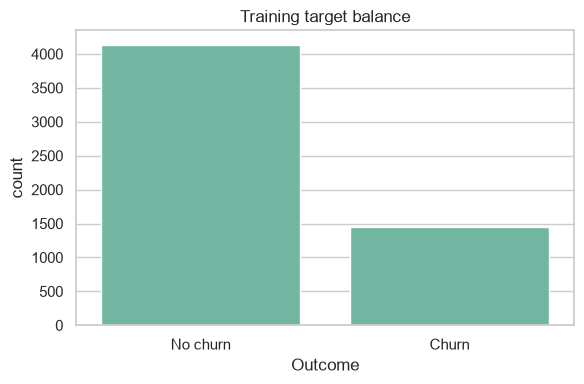

,count,mean,std,min,25%,50%,75%,max
age,5592.0,46.524142,16.697466,19.000000,33.000000,46.000000,60.000000,80.000000
num_dependents,5592.0,0.472639,0.965494,0.000000,0.000000,0.000000,0.000000,9.000000
tenure_months,5592.0,32.526824,24.594395,1.000000,9.000000,29.000000,56.000000,72.000000
num_referrals,5592.0,1.967811,3.015082,0.000000,0.000000,0.000000,3.000000,11.000000
avg_long_distance_fee_monthly,5592.0,22.967448,15.389445,0.000000,9.330000,22.950000,36.390000,49.990000
total_long_distance_fee,5592.0,755.695275,850.198424,0.000000,71.265000,411.305000,1200.395000,3564.720000
avg_gb_download_monthly,5592.0,20.577611,20.408370,0.000000,3.000000,17.000000,27.000000,85.000000
total_monthly_fee,5592.0,64.881438,30.096754,18.400000,35.800000,70.450000,89.850000,118.750000
total_charges_quarter,5592.0,2301.358573,2283.433638,18.800000,401.762500,1396.125000,3846.450000,8684.800000
total_refunds,5592.0,1.924197,7.837968,0.000000,0.000000,0.000000,0.000000,49.790000


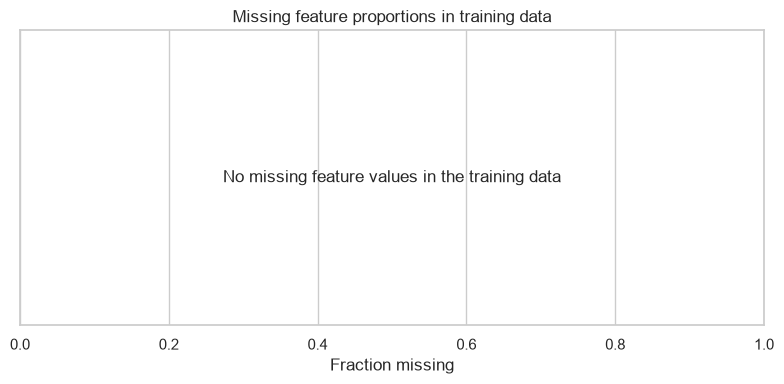

In [7]:
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=train, x='target', ax=ax)
ax.set(xticks=[0,1], xticklabels=['No churn','Churn'], title='Training target balance', xlabel='Outcome')
plt.tight_layout(); plt.show()
display(train[numeric_cols].describe().T)
fig, ax = plt.subplots(figsize=(8,4))
missing = train[category_cols + numeric_cols].isna().mean().sort_values(ascending=False)
if missing.gt(0).any():
    missing[missing.gt(0)].plot.barh(ax=ax)
else:
    ax.text(0.5,0.5,'No missing feature values in the training data',ha='center',va='center',transform=ax.transAxes)
    ax.set_yticks([])
ax.set(title='Missing feature proportions in training data', xlabel='Fraction missing')
plt.tight_layout(); plt.show()


### Step 5a — Numeric distributions and outliers
Compare tenure, fees, age and usage across outcomes. Extreme values are not automatically
errors; keep valid values and use scaling for Logistic Regression. No percentile thresholds
are estimated from the test data.


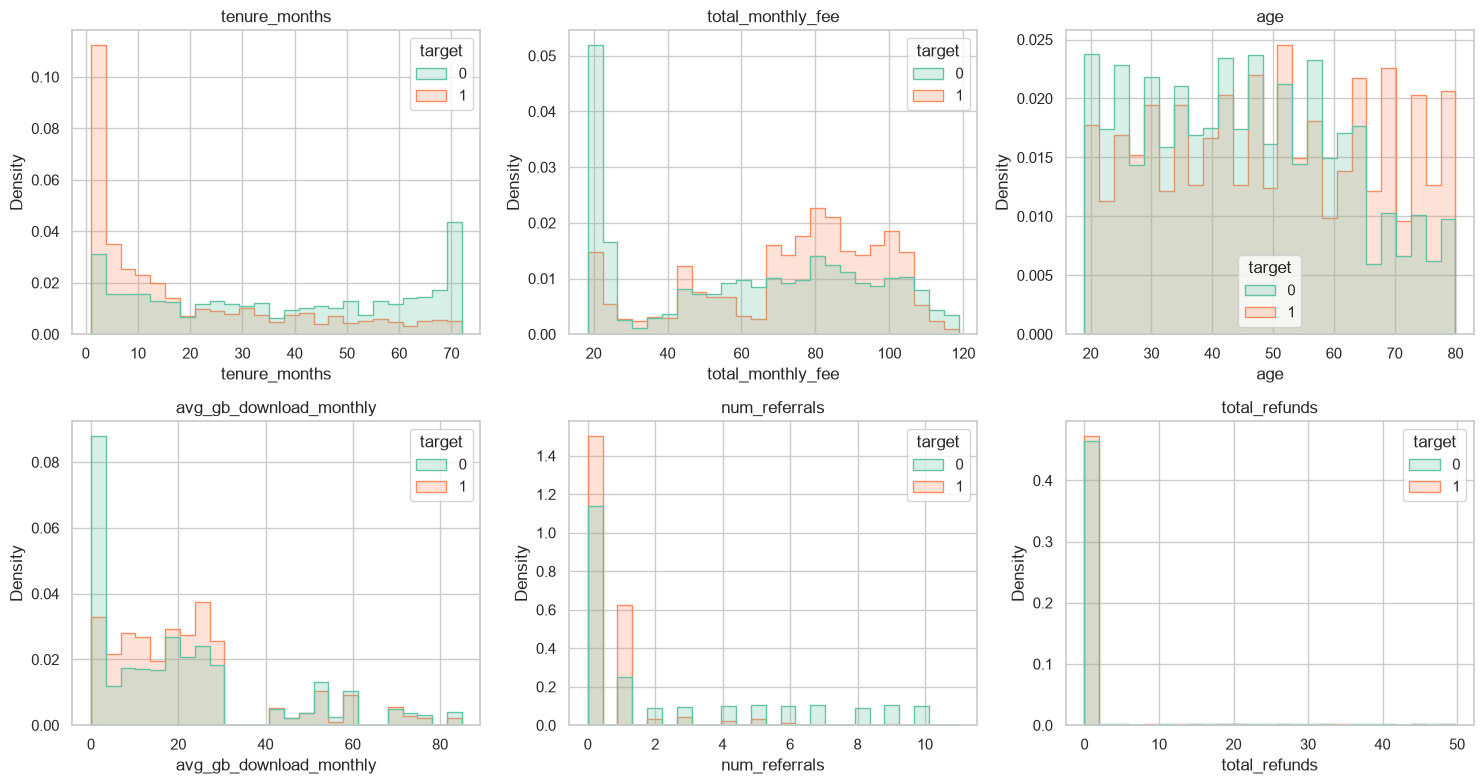

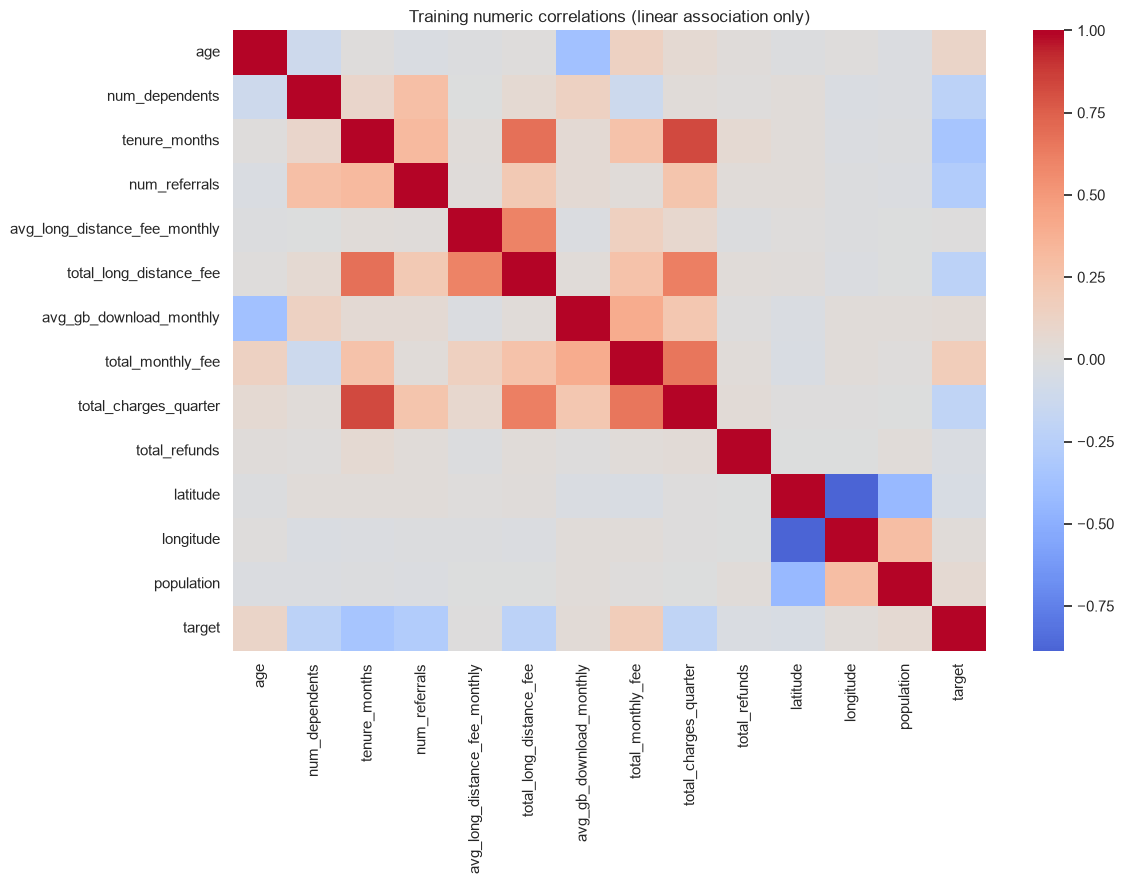

In [8]:
eda_numeric = ['tenure_months','total_monthly_fee','age','avg_gb_download_monthly','num_referrals','total_refunds']
fig, axes = plt.subplots(2,3,figsize=(15,8))
for col, ax in zip(eda_numeric, axes.flat):
    sns.histplot(data=train, x=col, hue='target', bins=25, stat='density', common_norm=False, element='step', ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(12,9))
sns.heatmap(train[numeric_cols + ['target']].corr(), cmap='coolwarm', center=0, ax=ax)
ax.set_title('Training numeric correlations (linear association only)')
plt.tight_layout(); plt.show()


### Step 5b — Churn rates by customer/service group
Always show group counts alongside rates: a high rate from a tiny group is unreliable.
Gender and senior status are included for research; any customer-care use needs a separate
fairness and suitability review. Their predictive association does not justify different treatment.


**contract_type**

,customers,churners,churn_rate
contract_type,,,
month-to-month,2836,1280,0.451340
one year,1244,133,0.106913
two year,1512,40,0.026455


**internet_type**

,customers,churners,churn_rate
internet_type,,,
fiber optic,2415,959,0.397101
cable,659,162,0.245827
dsl,1306,237,0.181470
none,1212,95,0.078383


**payment_method**

,customers,churners,churn_rate
payment_method,,,
mailed check,314,109,0.347134
bank withdrawal,3096,1028,0.332041
credit card,2182,316,0.144821


... (2 outputs left out)

**senior_citizen**

,customers,churners,churn_rate
senior_citizen,,,
yes,896,369,0.411830
no,4696,1084,0.230835


**gender**

,customers,churners,churn_rate
gender,,,
female,2748,731,0.266012
male,2844,722,0.253868


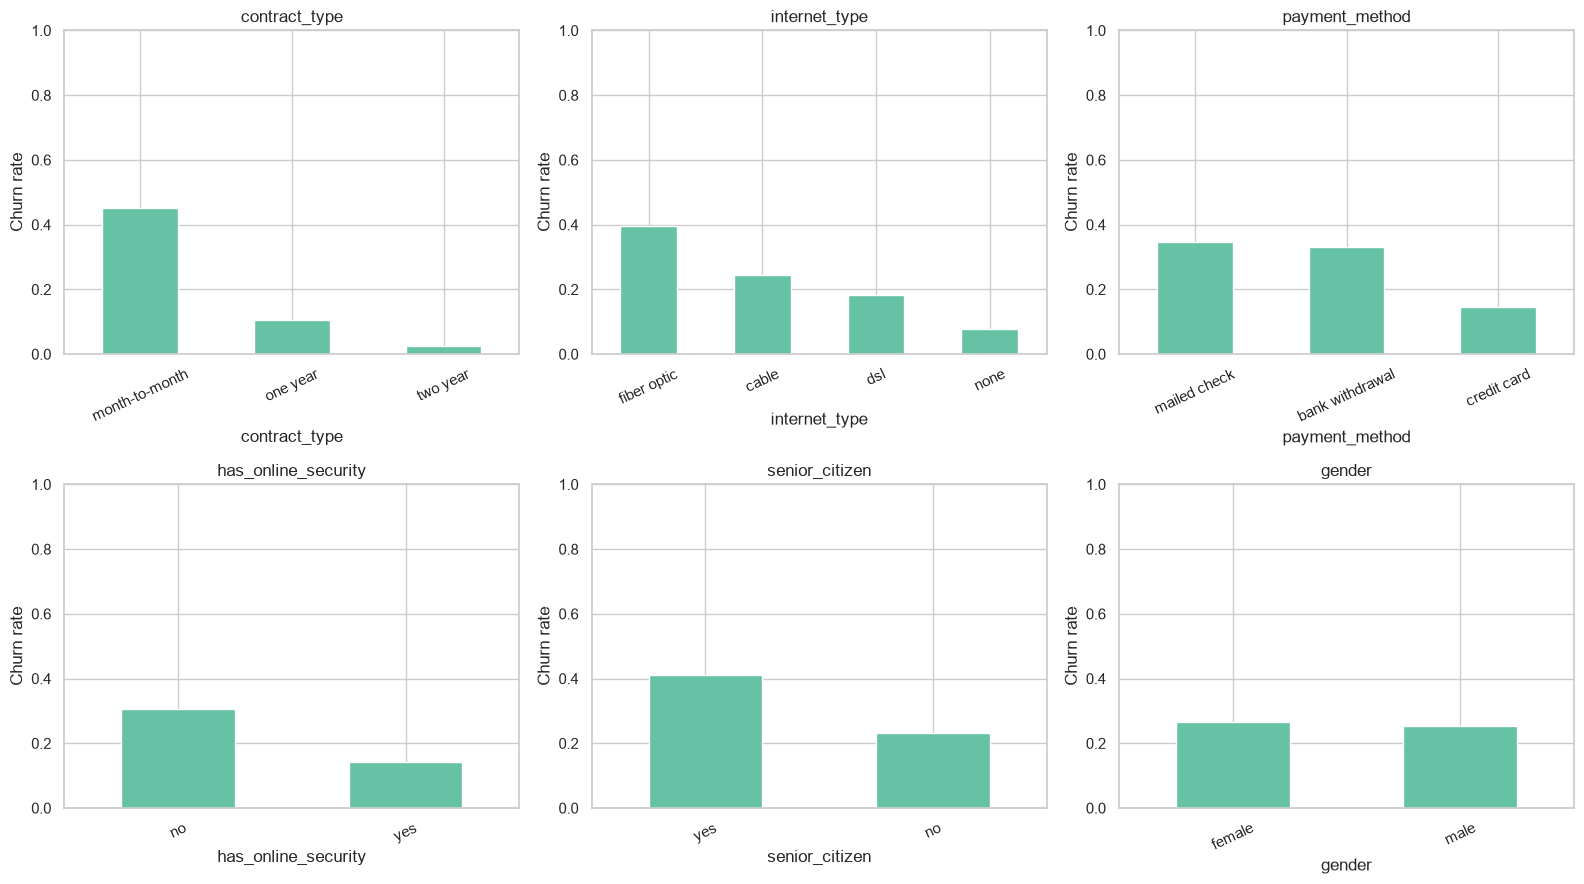

In [9]:
group_tables = {}
fig, axes = plt.subplots(2,3,figsize=(16,9))
for col, ax in zip(['contract_type','internet_type','payment_method','has_online_security','senior_citizen','gender'], axes.flat):
    tab = train.groupby(col, dropna=False).target.agg(customers='size', churners='sum', churn_rate='mean').sort_values('churn_rate', ascending=False)
    group_tables[col] = tab
    display(Markdown(f'**{col}**')); display(tab)
    tab.churn_rate.plot.bar(ax=ax)
    ax.set(title=col, ylabel='Churn rate', ylim=(0,1))
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()


## Step 6 — Engineer features with explicit business meaning
- `internet_type = no internet service` only when the service flag says No. A missing value
  for an internet subscriber stays unknown and is imputed inside the pipeline.
- Count selected support/security add-ons and streaming services. If any component is unknown,
  the count stays missing rather than treating unknown as No.
- `short_tenure` marks at most 12 months, a fixed business rule rather than a learned cutoff.
- `monthly_fee_per_service` divides monthly fees by the number of core services; zero core
  services yields missing rather than infinity.

Refund and quarterly totals may contain events after churn. **Conservatively exclude refunds,
quarterly charges and total long-distance fees** until their time windows are confirmed.
The other features still require a pre-churn availability check. Keep latitude, longitude and
population as broad location context; exclude raw IDs, ZIP, city and join flags.
All learned imputations, scaling and encoding will be fitted separately inside each CV fold.


In [10]:
def engineer_features(X):
    X = X.copy()
    X.loc[X.has_internet_service.eq('no'), 'internet_type'] = 'no internet service'
    addons = ['has_premium_tech_support','has_online_security','has_online_backup','has_device_protection']
    streams = ['stream_tv','stream_movie','stream_music']
    for name, cols in [('support_addon_count',addons), ('streaming_count',streams)]:
        bits = X[cols].apply(lambda s:s.map({'yes':1.0,'no':0.0}))
        X[name] = bits.sum(axis=1, min_count=len(cols))
    X['short_tenure'] = np.where(X.tenure_months.isna(), np.nan, (X.tenure_months <= 12).astype(float))
    core = X[['has_internet_service','has_phone_service']].apply(lambda s:s.map({'yes':1.0,'no':0.0})).sum(axis=1,min_count=2)
    X['monthly_fee_per_service'] = X.total_monthly_fee / core.replace(0,np.nan)
    return X.replace({pd.NA:np.nan})

excluded_numeric = ['total_refunds','total_charges_quarter','total_long_distance_fee']
base_numeric = [c for c in numeric_cols if c not in excluded_numeric]
engineered_numeric = ['support_addon_count','streaming_count','short_tenure','monthly_fee_per_service']
feature_cols = base_numeric + category_cols
X_train, y_train = train[feature_cols].copy(), train.target.copy()
X_test, y_test = test[feature_cols].copy(), test.target.copy()
leakage_cols = {'target','churn_label','status','customer_status','churn_category','churn_reason','customer_id','account_id'}
assert leakage_cols.isdisjoint(X_train.columns)
display(engineer_features(X_train)[engineered_numeric].describe().T)
print('Model inputs:', len(feature_cols), 'raw features plus', len(engineered_numeric), 'engineered features')


,count,mean,std,min,25%,50%,75%,max
support_addon_count,5592.0,1.270207,1.285050,0.0,0.000,1.000,2.000,4.0
streaming_count,5592.0,1.131617,1.251515,0.0,0.000,1.000,2.000,3.0
short_tenure,5592.0,0.309728,0.462423,0.0,0.000,0.000,1.000,1.0
monthly_fee_per_service,5592.0,36.711382,11.765481,18.4,25.225,37.575,46.275,67.2


Model inputs: 28 raw features plus 4 engineered features


## Step 7 — Build preprocessing and a baseline
Numeric values receive median imputation plus missingness indicators and standard scaling.
Categorical values receive an explicit unknown category and one-hot encoding. Unknown test
categories are handled without refitting. Both model families use the same transformations.
The dummy model is evaluated on identical folds and should have ROC AUC near 0.5.


In [11]:
def make_preprocessor():
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('impute',SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
            ('scale',StandardScaler())]), base_numeric + engineered_numeric),
        ('category', Pipeline([
            ('impute',SimpleImputer(strategy='constant',fill_value='unknown',keep_empty_features=True)),
            ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]), category_cols)
    ], remainder='drop')

def make_pipeline(model):
    return Pipeline([('engineer',FunctionTransformer(engineer_features,validate=False)),
                     ('prepare',make_preprocessor()), ('model',model)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
baseline_scores = cross_val_score(make_pipeline(DummyClassifier(strategy='prior')), X_train,y_train,cv=cv,scoring='roc_auc')
print(f'Dummy CV ROC AUC: {baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}')


Dummy CV ROC AUC: 0.5000 ± 0.0000


## Step 8 — Tune Logistic Regression
This is an interpretable linear baseline after one-hot encoding. Tune regularization strength
`C` (smaller means stronger regularization) and class weighting. Weighting is an experiment,
not an automatic fix for imbalance. Use predicted probabilities, not class labels, for AUC.


In [12]:
logistic_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=3000, solver='lbfgs', random_state=SEED)),
    param_grid={'model__C':[0.01,0.1,1.0,10.0], 'model__class_weight':[None,'balanced']},
    scoring='roc_auc', cv=cv, n_jobs=2, refit=True, return_train_score=True, error_score='raise')
logistic_search.fit(X_train,y_train)
print('Best parameters:', logistic_search.best_params_)
print('Best mean CV ROC AUC:', round(logistic_search.best_score_,4))


Best parameters: {'model__C': 10.0, 'model__class_weight': None}
Best mean CV ROC AUC: 0.8971


## Step 9 — Tune Random Forest
Random Forest can capture nonlinear relationships and interactions. Tune tree depth,
minimum leaf size, feature subsampling and class weighting. Fix 200 trees to keep the grid
manageable: 16 candidates × 5 folds. `n_jobs=1` inside the forest avoids nested parallelism.


In [13]:
forest_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1)),
    param_grid={'model__max_depth':[8,None], 'model__min_samples_leaf':[2,8],
                'model__max_features':['sqrt',0.6], 'model__class_weight':[None,'balanced']},
    scoring='roc_auc',cv=cv,n_jobs=2,refit=True,return_train_score=True,error_score='raise')
forest_search.fit(X_train,y_train)
print('Best parameters:', forest_search.best_params_)
print('Best mean CV ROC AUC:', round(forest_search.best_score_,4))


Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__max_features': 0.6, 'model__min_samples_leaf': 8}
Best mean CV ROC AUC: 0.9013


## Step 10 — Compare and lock the winner using CV only
Compare mean CV AUC, fold variability, training AUC and fit time. A large train–CV gap suggests
overfitting. Select the highest mean CV ROC AUC; exact ties favor Logistic Regression.
Fold standard deviations are descriptive, not confidence intervals. These are tuning scores,
so the untouched test set is needed to estimate the chosen model's generalization.


In [14]:
searches = {'Logistic Regression':logistic_search, 'Random Forest':forest_search}
rows=[]
for name, search in searches.items():
    i=search.best_index_; r=search.cv_results_
    rows.append({'model':name,'cv_auc_mean':r['mean_test_score'][i],
                 'cv_auc_std':r['std_test_score'][i], 'train_auc_mean':r['mean_train_score'][i],
                 'mean_fit_seconds':r['mean_fit_time'][i], 'best_parameters':str(search.best_params_)})
    pd.DataFrame(r).to_csv(OUTPUT / (name.lower().replace(' ','_') + '_cv_results.csv'),index=False)
comparison = pd.DataFrame(rows).sort_values('cv_auc_mean',ascending=False,kind='stable').reset_index(drop=True)
display(comparison)
winner_name = comparison.loc[0,'model']
winner_search = searches[winner_name]
winner = winner_search.best_estimator_  # Already refitted on all training data, never on test data.
print('Locked selection:', winner_name)
comparison.to_csv(OUTPUT / 'model_comparison.csv',index=False)


,model,cv_auc_mean,cv_auc_std,train_auc_mean,mean_fit_seconds,best_parameters
0,Random Forest,0.901294,0.008984,0.975102,8.865949,"{'model__class_weight': 'balanced', 'model__ma..."
1,Logistic Regression,0.897118,0.010141,0.903025,0.387459,"{'model__C': 10.0, 'model__class_weight': None}"


Locked selection: Random Forest


## Step 11 — Evaluate the selected model once on the reserved test set
Report ROC AUC first, then average precision, ROC/PR curves and threshold-dependent diagnostics.
The 0.5 threshold is illustrative. Operational thresholds depend on outreach capacity and the
costs of missed churn versus unnecessary contact; do not tune them against this test set.
Do not switch model families after seeing these results. A later research cycle requires a
new validation plan.


Random Forest: test ROC AUC = 0.9068; test average precision = 0.7876
              precision    recall  f1-score   support

    No churn       0.93      0.82      0.87      1035
       Churn       0.62      0.84      0.71       364

    accuracy                           0.82      1399
   macro avg       0.78      0.83      0.79      1399
weighted avg       0.85      0.82      0.83      1399



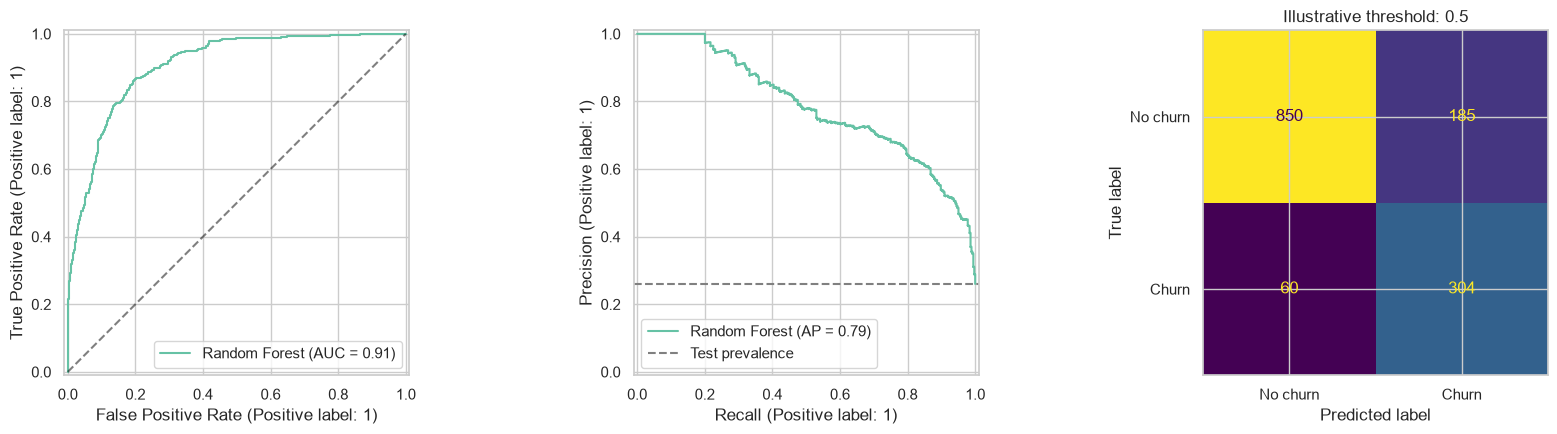

Approximate 95% bootstrap interval for test ROC AUC: [0.8904, 0.9233]


In [15]:
test_probability = winner.predict_proba(X_test)[:,1]
test_prediction = (test_probability >= 0.5).astype(int)
test_auc = roc_auc_score(y_test,test_probability)
test_ap = average_precision_score(y_test,test_probability)
print(f'{winner_name}: test ROC AUC = {test_auc:.4f}; test average precision = {test_ap:.4f}')
print(classification_report(y_test,test_prediction,target_names=['No churn','Churn'],zero_division=0))
fig, axes = plt.subplots(1,3,figsize=(17,4.5))
RocCurveDisplay.from_predictions(y_test,test_probability,ax=axes[0],name=winner_name)
axes[0].plot([0,1],[0,1],'k--',alpha=0.5)
PrecisionRecallDisplay.from_predictions(y_test,test_probability,ax=axes[1],name=winner_name)
axes[1].axhline(y_test.mean(),color='grey',linestyle='--',label='Test prevalence'); axes[1].legend()
ConfusionMatrixDisplay.from_predictions(y_test,test_prediction,ax=axes[2],display_labels=['No churn','Churn'],colorbar=False)
axes[2].set_title('Illustrative threshold: 0.5')
plt.tight_layout(); plt.show()

# Stratified bootstrap: uncertainty for this fixed fitted model, not the whole tuning procedure.
rng=np.random.default_rng(SEED)
y_arr=y_test.to_numpy(); ix0=np.flatnonzero(y_arr==0); ix1=np.flatnonzero(y_arr==1)
boot_auc=[]
for _ in range(1000):
    idx=np.r_[rng.choice(ix0,len(ix0),replace=True),rng.choice(ix1,len(ix1),replace=True)]
    boot_auc.append(roc_auc_score(y_arr[idx],test_probability[idx]))
auc_low, auc_high = np.quantile(boot_auc,[0.025,0.975])
print(f'Approximate 95% bootstrap interval for test ROC AUC: [{auc_low:.4f}, {auc_high:.4f}]')


## Step 12 — Inspect which inputs the selected model uses
Permutation importance measures how much AUC falls when one original feature is shuffled.
Compute it on a training subset for descriptive interpretation only; training importance can
be optimistic and correlated features can share or hide importance. This is not a causal
effect or a new feature-selection loop. Engineered features are recomputed by the pipeline
when their source columns are shuffled.


,feature,auc_drop_mean,auc_drop_std
26,contract_type,0.213987,0.009609
3,num_referrals,0.077291,0.002147
2,tenure_months,0.055952,0.003296
6,total_monthly_fee,0.047647,0.002905
1,num_dependents,0.027126,0.003326
0,age,0.010784,0.000643
7,latitude,0.008447,0.000324
27,payment_method,0.008084,0.000886
9,population,0.007918,0.000492
4,avg_long_distance_fee_monthly,0.007555,0.000193


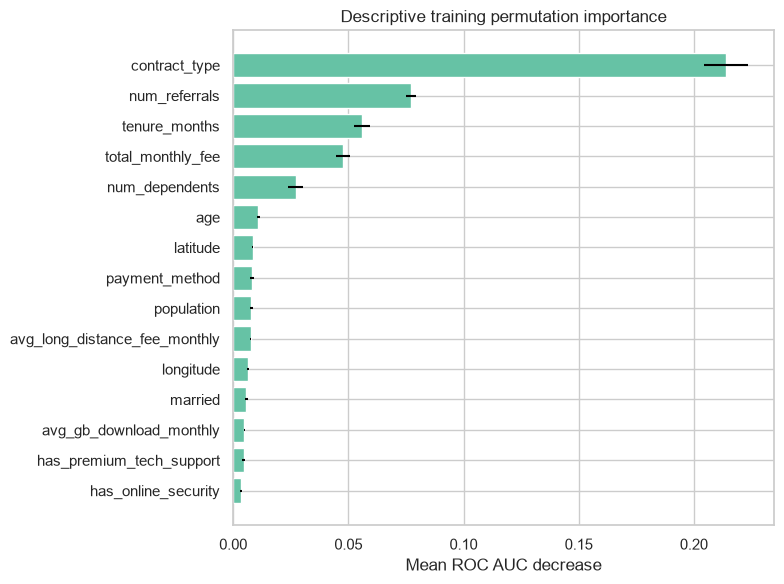

In [16]:
importance_sample = X_train.sample(n=min(1500,len(X_train)),random_state=SEED)
importance = permutation_importance(winner,importance_sample,y_train.loc[importance_sample.index],
                                    scoring='roc_auc',n_repeats=3,random_state=SEED,n_jobs=2)
importance_table = pd.DataFrame({'feature':feature_cols,'auc_drop_mean':importance.importances_mean,
                                 'auc_drop_std':importance.importances_std}).sort_values('auc_drop_mean',ascending=False)
display(importance_table.head(15))
fig, ax=plt.subplots(figsize=(8,6))
top=importance_table.head(15).sort_values('auc_drop_mean')
ax.barh(top.feature,top.auc_drop_mean,xerr=top.auc_drop_std)
ax.set(title='Descriptive training permutation importance',xlabel='Mean ROC AUC decrease')
plt.tight_layout(); plt.show()
importance_table.to_csv(OUTPUT / 'feature_importance.csv',index=False)


## Step 13 — Record the evidence and Stage 1 recommendation
The following output is generated from this run, so findings and scores are not invented.
Research metrics/configuration are saved locally; no model `.pkl`, app or deployment is produced.
Repeatedly inspecting the same test results does not create new independent evidence.


In [17]:
contract_summary = group_tables['contract_type'].sort_values('churn_rate',ascending=False)
top_contract = contract_summary.index[0]
top_features = ', '.join(importance_table.head(5).feature)
summary = f"""### Stage 1 findings from this execution
- Retrieved **{len(raw):,}** customer records; **{df.churn_label.isna().sum():,}** lacked the target and were excluded.
- Training set: **{len(train):,}** customers, churn rate **{y_train.mean():.2%}**.
- The highest observed training churn rate by contract is **{top_contract}**
  (**{contract_summary.iloc[0].churn_rate:.2%}**, n={int(contract_summary.iloc[0].customers):,}). This is an association.
- Selected **{winner_name}** by mean CV ROC AUC **{winner_search.best_score_:.4f}**.
- Reserved-test ROC AUC: **{test_auc:.4f}** (approximate bootstrap interval **{auc_low:.4f}–{auc_high:.4f}**).
- Reserved-test average precision: **{test_ap:.4f}**.
- Most influential original inputs in the descriptive training permutation analysis: **{top_features}**.

**Recommendation:** carry the selected configuration forward as the Stage 1 candidate, subject
to confirming feature timestamps and validating on a later customer snapshot before operational use.
"""
display(Markdown(summary))
manifest = {
    'extracted_utc':datetime.now(timezone.utc).isoformat(), 'schema':DB_SCHEMA,
    'snapshot_sha256':snapshot_sha256, 'raw_customers':len(raw), 'labeled_customers':len(labeled),
    'missing_labels':int(df.churn_label.isna().sum()), 'random_seed':SEED,
    'train_customers':len(train), 'test_customers':len(test), 'cv_folds':5,
    'selected_model':winner_name, 'best_parameters':winner_search.best_params_,
    'cv_roc_auc':float(winner_search.best_score_), 'test_roc_auc':float(test_auc),
    'test_average_precision':float(test_ap), 'test_auc_bootstrap_95':[float(auc_low),float(auc_high)],
    'versions':{'python':platform.python_version(),'pandas':pd.__version__,'sklearn':sklearn.__version__},
    'features':feature_cols, 'engineered_features':engineered_numeric,
    'conservatively_excluded':excluded_numeric}
(OUTPUT / 'research_summary.md').write_text(summary,encoding='utf-8')
(OUTPUT / 'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Research evidence saved in:', OUTPUT.resolve())


### Stage 1 findings from this execution
- Retrieved **7,043** customer records; **52** lacked the target and were excluded.
- Training set: **5,592** customers, churn rate **25.98%**.
- The highest observed training churn rate by contract is **month-to-month**
  (**45.13%**, n=2,836). This is an association.
- Selected **Random Forest** by mean CV ROC AUC **0.9013**.
- Reserved-test ROC AUC: **0.9068** (approximate bootstrap interval **0.8904–0.9233**).
- Reserved-test average precision: **0.7876**.
- Most influential original inputs in the descriptive training permutation analysis: **contract_type, num_referrals, tenure_months, total_monthly_fee, num_dependents**.

**Recommendation:** carry the selected configuration forward as the Stage 1 candidate, subject
to confirming feature timestamps and validating on a later customer snapshot before operational use.


Research evidence saved in: C:\Users\User\OneDrive\Desktop\AI300\stage1_outputs


## Step 14 — Interpretation checklist and limits
1. **Coverage:** review match flags, missing labels, key checks and target balance before trusting scores.
2. **Availability:** confirm service fields, monthly usage, age and tenure were known before churn.
   Refunds and quarterly totals remain excluded until their timing is established.
3. **Missingness:** non-subscribers have structural missing internet type; true unknowns are handled separately.
4. **Generalization:** this is one random split of a single retrospective snapshot. It does not test future
   months, new cities or a changed customer population. CV tuning scores can be optimistic.
5. **Business use:** high AUC does not mean well-calibrated probabilities or effective retention offers.
   Threshold selection, fairness checks and prospective evaluation need separate work.
6. **Stage boundary:** stop here for Stage 1. Model serialization, the required `Model` class,
   Flask `/predict` and deployment are later milestones.

### References
- Local project brief and data dictionary listed at the beginning of this notebook.
- [scikit-learn: avoiding data leakage with pipelines](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn: cross-validation and held-out evaluation](https://scikit-learn.org/stable/modules/cross_validation.html).
- [scikit-learn: GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
